<a href="https://colab.research.google.com/github/aakankshalahane/NLP-Projects-/blob/main/LLM_Response_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# PROJECT 1: LLM RESPONSE EVALUATION

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")



Libraries imported successfully!


In [ ]:
#Sample dataset

# Create sample dataset

data = {
    "Question": [
        "What is Artificial Intelligence?",
        "What is Python?",
        "What is Machine Learning?",
        "What is Deep Learning?",
        "What is NLP?",
        "What is Computer Vision?",
        "What is Data Annotation?",
        "What is Generative AI?",
        "What is a Neural Network?",
        "What is an LLM?"
    ],

    "Response_A": [
        "AI is the simulation of human intelligence by machines.",
        "Python is a high-level programming language.",
        "Machine Learning enables computers to learn patterns from data.",
        "Deep Learning uses multiple layers of neural networks.",
        "NLP helps computers understand and process human language.",
        "Computer Vision enables computers to interpret images and videos.",
        "Data Annotation is the process of labeling data for machine learning.",
        "Generative AI creates new content such as text, images and audio.",
        "A neural network is a computing model inspired by the human brain.",
        "An LLM is a large language model trained on large amounts of text."
    ],

    "Response_B": [
        "Artificial Intelligence is a type of computer hardware.",
        "Python is a type of database.",
        "Machine Learning is only used for making websites.",
        "Deep Learning is a spreadsheet application.",
        "NLP means Network Learning Process.",
        "Computer Vision is used only for editing photos.",
        "Data Annotation means deleting unnecessary data.",
        "Generative AI only performs mathematical calculations.",
        "A neural network is a computer storage device.",
        "An LLM is a programming language."
    ],

    "Expected_Better_Response": [
        "A", "A", "A", "A", "A",
        "A", "A", "A", "A", "A"
    ]
}

df = pd.DataFrame(data)

# Display dataset

df.head(10)


,Question,Response_A,Response_B,Expected_Better_Response
0,What is Artificial Intelligence?,AI is the simulation of human intelligence by ...,Artificial Intelligence is a type of computer ...,A
1,What is Python?,Python is a high-level programming language.,Python is a type of database.,A
2,What is Machine Learning?,Machine Learning enables computers to learn pa...,Machine Learning is only used for making websi...,A
3,What is Deep Learning?,Deep Learning uses multiple layers of neural n...,Deep Learning is a spreadsheet application.,A
4,What is NLP?,NLP helps computers understand and process hum...,NLP means Network Learning Process.,A
5,What is Computer Vision?,Computer Vision enables computers to interpret...,Computer Vision is used only for editing photos.,A
6,What is Data Annotation?,Data Annotation is the process of labeling dat...,Data Annotation means deleting unnecessary data.,A
7,What is Generative AI?,Generative AI creates new content such as text...,Generative AI only performs mathematical calcu...,A
8,What is a Neural Network?,A neural network is a computing model inspired...,A neural network is a computer storage device.,A
9,What is an LLM?,An LLM is a large language model trained on la...,An LLM is a programming language.,A


In [ ]:

# Define evaluation rubric

evaluation_criteria = {
    "Accuracy": "Factual correctness",
    "Relevance": "Answers the given question",
    "Clarity": "Easy to understand",
    "Completeness": "Contains sufficient information",
    "Helpfulness": "Useful to the user"
}

for criterion, description in evaluation_criteria.items():
    print(criterion, ":", description)


Accuracy : Factual correctness
Relevance : Answers the given question
Clarity : Easy to understand
Completeness : Contains sufficient information
Helpfulness : Useful to the user


In [ ]:

# Manual evaluation scores

scores = {
    "A_Accuracy":     [5, 5, 5, 5, 5, 5, 5, 5, 5, 5],
    "A_Relevance":    [5, 5, 5, 5, 5, 5, 5, 5, 5, 5],
    "A_Clarity":      [5, 5, 5, 5, 5, 5, 5, 5, 5, 5],
    "A_Completeness": [4, 4, 4, 4, 4, 4, 4, 4, 4, 4],
    "A_Helpfulness":  [5, 5, 5, 5, 5, 5, 5, 5, 5, 5],

    "B_Accuracy":     [1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
    "B_Relevance":    [2, 2, 2, 2, 2, 2, 2, 2, 2, 2],
    "B_Clarity":      [3, 3, 3, 3, 3, 3, 3, 3, 3, 3],
    "B_Completeness": [1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
    "B_Helpfulness":  [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
}

score_df = pd.DataFrame(scores)

# Combine with original dataset

evaluation_df = pd.concat([df, score_df], axis=1)

evaluation_df.head()


,Question,Response_A,Response_B,Expected_Better_Response,A_Accuracy,A_Relevance,A_Clarity,A_Completeness,A_Helpfulness,B_Accuracy,B_Relevance,B_Clarity,B_Completeness,B_Helpfulness
0,What is Artificial Intelligence?,AI is the simulation of human intelligence by ...,Artificial Intelligence is a type of computer ...,A,5,5,5,4,5,1,2,3,1,1
1,What is Python?,Python is a high-level programming language.,Python is a type of database.,A,5,5,5,4,5,1,2,3,1,1
2,What is Machine Learning?,Machine Learning enables computers to learn pa...,Machine Learning is only used for making websi...,A,5,5,5,4,5,1,2,3,1,1
3,What is Deep Learning?,Deep Learning uses multiple layers of neural n...,Deep Learning is a spreadsheet application.,A,5,5,5,4,5,1,2,3,1,1
4,What is NLP?,NLP helps computers understand and process hum...,NLP means Network Learning Process.,A,5,5,5,4,5,1,2,3,1,1


In [ ]:

# Calculate total evaluation scores

evaluation_df["Total_Score_A"] = (
    evaluation_df[
        ["A_Accuracy", "A_Relevance", "A_Clarity",
         "A_Completeness", "A_Helpfulness"]
    ].sum(axis=1)
)

evaluation_df["Total_Score_B"] = (
    evaluation_df[
        ["B_Accuracy", "B_Relevance", "B_Clarity",
         "B_Completeness", "B_Helpfulness"]
    ].sum(axis=1)
)

evaluation_df[
    ["Question", "Total_Score_A", "Total_Score_B"]
]


,Question,Total_Score_A,Total_Score_B
0,What is Artificial Intelligence?,24,8
1,What is Python?,24,8
2,What is Machine Learning?,24,8
3,What is Deep Learning?,24,8
4,What is NLP?,24,8
5,What is Computer Vision?,24,8
6,What is Data Annotation?,24,8
7,What is Generative AI?,24,8
8,What is a Neural Network?,24,8
9,What is an LLM?,24,8


In [ ]:

# Compare AI responses

def select_best_response(row):

    if row["Total_Score_A"] > row["Total_Score_B"]:
        return "A"

    elif row["Total_Score_B"] > row["Total_Score_A"]:
        return "B"

    else:
        return "Tie"


evaluation_df["Selected_Response"] = evaluation_df.apply(
    select_best_response,
    axis=1
)

evaluation_df[
    ["Question", "Selected_Response", "Expected_Better_Response"]
]


,Question,Selected_Response,Expected_Better_Response
0,What is Artificial Intelligence?,A,A
1,What is Python?,A,A
2,What is Machine Learning?,A,A
3,What is Deep Learning?,A,A
4,What is NLP?,A,A
5,What is Computer Vision?,A,A
6,What is Data Annotation?,A,A
7,What is Generative AI?,A,A
8,What is a Neural Network?,A,A
9,What is an LLM?,A,A


In [ ]:

# Calculate preference accuracy

accuracy = accuracy_score(
    evaluation_df["Expected_Better_Response"],
    evaluation_df["Selected_Response"]
)

print("Preference Evaluation Accuracy:",
      round(accuracy * 100, 2), "%")

print("\nClassification Report:")

print(classification_report(
    evaluation_df["Expected_Better_Response"],
    evaluation_df["Selected_Response"],
    zero_division=0
))


Preference Evaluation Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

           A       1.00      1.00      1.00        10

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10



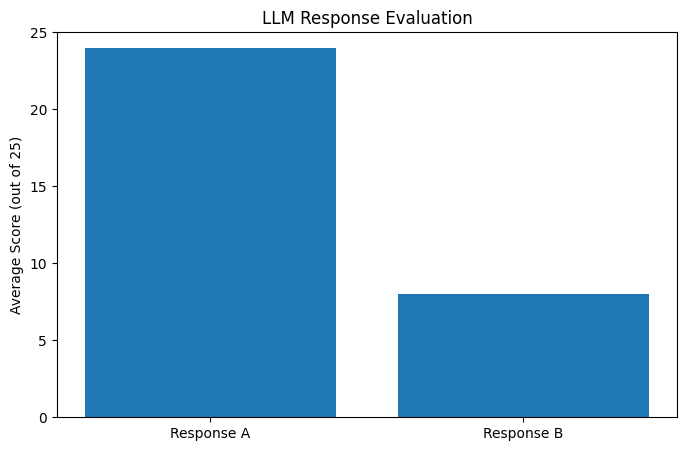

In [ ]:

# Compare average response scores

average_scores = [
    evaluation_df["Total_Score_A"].mean(),
    evaluation_df["Total_Score_B"].mean()
]

labels = ["Response A", "Response B"]

plt.figure(figsize=(8, 5))

plt.bar(labels, average_scores)

plt.title("LLM Response Evaluation")
plt.ylabel("Average Score (out of 25)")
plt.ylim(0, 25)

plt.show()


In [ ]:

# Export final evaluation results

evaluation_df.to_csv(
    "LLM_Response_Evaluation_Results.csv",
    index=False
)

print("Evaluation dataset exported successfully!")


Evaluation dataset exported successfully!


In [ ]:

from google.colab import files

files.download("LLM_Response_Evaluation_Results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Final project summary

print("PROJECT: LLM RESPONSE EVALUATION")

print("--------------------------------")

print("Total Questions:",
      len(evaluation_df))

print("Response A Wins:",
      (evaluation_df["Selected_Response"] == "A").sum())

print("Response B Wins:",
      (evaluation_df["Selected_Response"] == "B").sum())

print("Ties:",
      (evaluation_df["Selected_Response"] == "Tie").sum())

print("Reference Agreement:",
      round(accuracy * 100, 2), "%")

print("--------------------------------")

print("Project completed successfully!")


PROJECT: LLM RESPONSE EVALUATION
--------------------------------
Total Questions: 10
Response A Wins: 10
Response B Wins: 0
Ties: 0
Reference Agreement: 100.0 %
--------------------------------
Project completed successfully!
